# Create an "annual mean temperature" map which is split between hot/cold mortality

In [2]:
import os
import time
import glob
import json
import pandas as pd
import numpy as np
import xarray as xr
from utils.mortality_utils import mortality
from utils.utils import get_scenario_config, adjust_longitude, standardise_latlon
import config
from utils.utils import require_dir
import pathlib
import matplotlib.pyplot as plt

In [3]:
TMREL_DIR = require_dir(pathlib.Path(config.WORK_ROOT) / "GBD23" / "TMREL" / "summaries")
# Load mean tmrel at all gridcells
tmrel_map = xr.open_dataarray(TMREL_DIR/"tmrel_mean_0.25_map.nc")

In [4]:
def process_mortality(temp, tmrel):
    """ Split temperature to hot and cold, like we do with mortality """

    # Create mask for cold related and heat related deaths
    cold = xr.where(temp < tmrel, 1, 0)
    hot = xr.where(temp > tmrel, 1, 0)
    # select mortality, nan where cold/hot is 0
    cold_death_temps = temp.where(cold == 1).drop_vars("annual_temperature")
    heat_death_temps = temp.where(hot == 1).drop_vars("annual_temperature")

    cold_temps = cold_death_temps.mean("time")
    hot_temps = heat_death_temps.mean("time")

    return cold_temps, hot_temps

In [5]:
temp = xr.open_dataarray("/glade/derecho/scratch/arielm/Olympics/ARISE-SAI-1.5-downscaled/TREFHT/SSP2-4.5/bc_TREFHT_SSP245_ens001_2050.nc")

temp = adjust_longitude(standardise_latlon(temp - 273.15))

In [6]:
annual = temp.mean("time")        # (lat, lon), assumes one year per file

# Find tmrel based on annual mean temperature at each grid cell
tmrel_everywhere = tmrel_map.sel(annual_temperature=annual, method="nearest")

In [7]:
# Create mask for cold related and heat related deaths
cold = xr.where(temp < tmrel_everywhere, 1, 0)
hot = xr.where(temp > tmrel_everywhere, 1, 0)
# select mortality, nan where cold/hot is 0
cold_death_temps = temp.where(cold == 1).drop_vars("annual_temperature")
heat_death_temps = temp.where(hot == 1).drop_vars("annual_temperature")

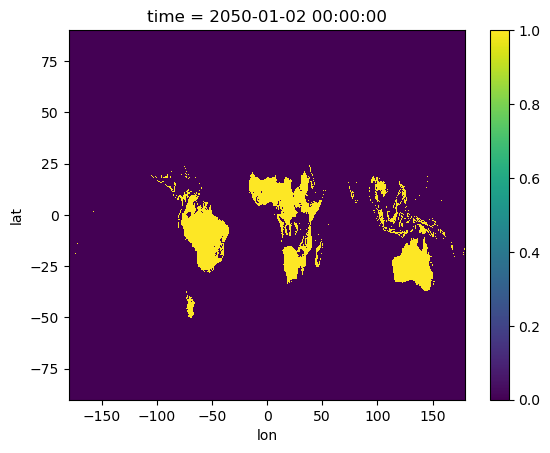

In [11]:
hot[1,:,:].plot()

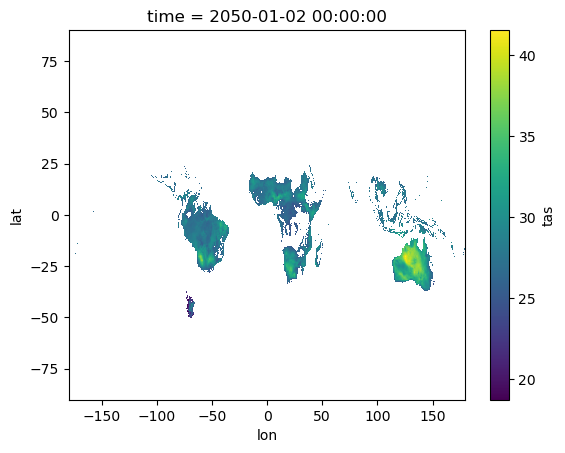

In [13]:
heat_death_temps[1,:,:].plot()

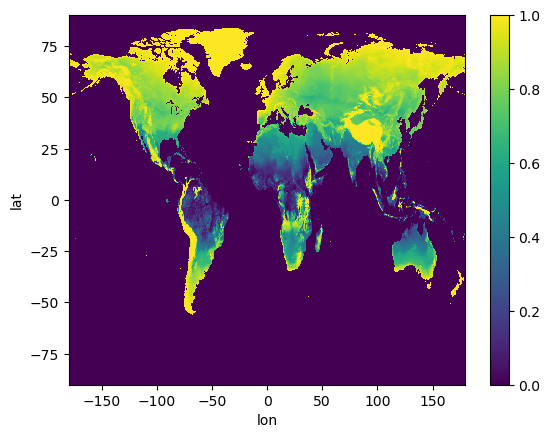

In [18]:
cold.mean("time").plot()

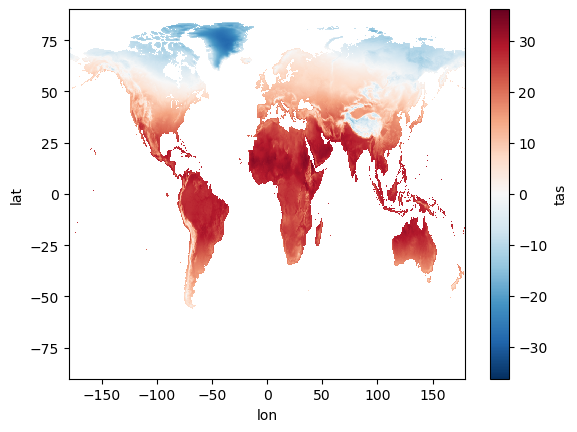

In [15]:
annual.where(tmrel_everywhere.notnull()).plot()

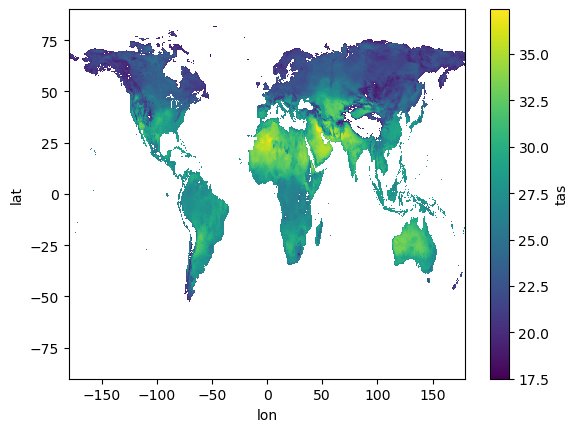

In [16]:
heat_death_temps.mean("time").plot()

In [ ]:
# === Path config ===
TEMP_DIR = "/glade/derecho/scratch/arielm/Olympics/ARISE-SAI-1.5-downscaled/TREFHT/SSP2-4.5/"